# The undercut

**Question:** when a driver pits before the car ahead to gain the position, how often does it work, and how many seconds does it gain on each circuit?

**Data:** all laps from `fct_laps`. The running order and the gap to the car ahead at each lap are rebuilt from the time each driver crosses the line (`lap_started_at`).

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DB_PATH = Path("../data/f1.duckdb")
IMAGES_DIR = Path("../images")
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

with duckdb.connect(str(DB_PATH), read_only=True) as con:
    laps = con.sql(
        """
        select
            session_key,
            season,
            circuit_name,
            driver_number,
            driver_code,
            team_name,
            lap_number,
            lap_started_at,
            lap_time_s,
            compound,
            tyre_age_laps,
            is_pit_in_lap,
            is_pit_out_lap,
            neutralisation
        from fct_laps
        where lap_started_at is not null
        """
    ).df()

laps = laps.sort_values(["session_key", "lap_number", "lap_started_at"])
by_lap = laps.groupby(["session_key", "lap_number"])
laps["position"] = by_lap.cumcount() + 1
laps["gap_ahead_s"] = by_lap["lap_started_at"].diff().dt.total_seconds()

print(laps.shape)

(99498, 16)


In [2]:
check = laps[
    (laps["season"] == 2025) & (laps["circuit_name"] == "Monza") & (laps["lap_number"] == 30)
]
check[["position", "driver_code", "team_name", "gap_ahead_s", "compound", "tyre_age_laps"]].head(10)

,position,driver_code,team_name,gap_ahead_s,compound,tyre_age_laps
73882,1,VER,Red Bull Racing,NaN,MEDIUM,29
33917,2,NOR,McLaren,6.226,MEDIUM,29
30480,3,PIA,McLaren,6.183,MEDIUM,29
21392,4,LEC,Ferrari,6.580,MEDIUM,29
14985,5,HAM,Ferrari,6.930,MEDIUM,29
92514,6,ALB,Williams,13.307,HARD,29
18492,7,SAI,Williams,2.444,MEDIUM,29
8815,8,OCO,Haas F1 Team,0.812,HARD,29
61624,9,STR,Aston Martin,1.000,HARD,30
42861,10,HAD,Racing Bulls,0.750,HARD,30


## How precise is `lap_started_at`?

OpenF1 describes the lap start time as approximate. Check: for each driver, the time elapsed between the start of two consecutive laps must equal the lap time of the first one.

In [3]:
laps = laps.sort_values(["session_key", "driver_number", "lap_number"])
by_driver = laps.groupby(["session_key", "driver_number"])

elapsed_s = by_driver["lap_started_at"].diff().dt.total_seconds()
previous_lap_time_s = by_driver["lap_time_s"].shift()
consecutive = by_driver["lap_number"].diff() == 1

laps["timing_error_s"] = (elapsed_s - previous_lap_time_s).where(consecutive)

laps["timing_error_s"].abs().describe(percentiles=[0.5, 0.9, 0.99]).round(3)

count    97658.000
mean         0.518
std         28.462
min          0.000
50%          0.047
90%          0.130
99%          0.300
max       4181.990
Name: timing_error_s, dtype: float64

The median error is 0.047 s and 99% of laps are within 0.30 s: precise enough for undercut gains of one second or more. The largest errors are laps interrupted by red flags, where the elapsed time includes the suspension.

## Finding undercut attempts

An undercut attempt is defined as:

1. the **attacker** pits under green flag;
2. at the start of the attacker's in-lap, the attacker is directly behind the **defender**, within 3 seconds;
3. the defender pits under green flag 1 to 3 laps later.

In [4]:
MAX_GAP_S = 3.0
MAX_LAPS_LATER = 3

green_pits = laps.loc[
    laps["is_pit_in_lap"] & laps["neutralisation"].isna(),
    ["session_key", "driver_number", "lap_number"],
]

# 1-2. Attackers: drivers pitting while within MAX_GAP_S of the car ahead.
# Lap 1 is excluded: every driver has the same lap 1 start time, so the
# running order and the gaps at the start of lap 1 are not measurable
attackers = laps.merge(green_pits, on=["session_key", "driver_number", "lap_number"])
attackers = attackers.loc[
    (attackers["lap_number"] > 1)
    & (attackers["position"] > 1)
    & (attackers["gap_ahead_s"] <= MAX_GAP_S),
    [
        "session_key", "season", "circuit_name", "driver_number", "driver_code",
        "lap_number", "position", "gap_ahead_s", "compound", "tyre_age_laps",
    ],
].rename(
    columns={
        "driver_number": "attacker",
        "driver_code": "attacker_code",
        "lap_number": "attacker_pit_lap",
        "gap_ahead_s": "gap_before_s",
        "compound": "attacker_old_compound",
        "tyre_age_laps": "attacker_old_tyre_age",
    }
)

# The car directly ahead of the attacker at that moment: the defender
ahead = laps[["session_key", "lap_number", "position", "driver_number", "driver_code"]].rename(
    columns={
        "lap_number": "attacker_pit_lap",
        "driver_number": "defender",
        "driver_code": "defender_code",
    }
)
ahead["position"] = ahead["position"] + 1
attempts = attackers.merge(ahead, on=["session_key", "attacker_pit_lap", "position"])

# 3. The defender pits 1 to MAX_LAPS_LATER laps later (first such stop)
defender_pits = green_pits.rename(
    columns={"driver_number": "defender", "lap_number": "defender_pit_lap"}
)
attempts = attempts.merge(defender_pits, on=["session_key", "defender"])
attempts = attempts[
    (attempts["defender_pit_lap"] > attempts["attacker_pit_lap"])
    & (attempts["defender_pit_lap"] <= attempts["attacker_pit_lap"] + MAX_LAPS_LATER)
]
attempts = attempts.sort_values("defender_pit_lap").drop_duplicates(
    ["session_key", "attacker", "attacker_pit_lap"]
)

print(f"Undercut attempts: {len(attempts)}")
attempts[
    ["season", "circuit_name", "attacker_code", "defender_code",
     "attacker_pit_lap", "defender_pit_lap", "gap_before_s", "attacker_old_compound"]
].head(10)

Undercut attempts: 218


,season,circuit_name,attacker_code,defender_code,attacker_pit_lap,defender_pit_lap,gap_before_s,attacker_old_compound
223,2023,Zandvoort,OCO,HAM,2,3,0.406,SOFT
157,2023,Zandvoort,ALO,NOR,2,3,0.531,SOFT
538,2024,Melbourne,ALB,MAG,6,7,0.432,HARD
566,2024,Suzuka,HUL,ZHO,5,7,0.698,SOFT
574,2024,Suzuka,BOT,TSU,6,7,0.735,SOFT
532,2024,Melbourne,MAG,BOT,7,8,2.024,HARD
134,2023,Spa-Francorchamps,BOT,SAR,6,8,0.344,SOFT
940,2024,Shanghai,HUL,BOT,8,9,0.574,MEDIUM
543,2024,Melbourne,HAM,TSU,7,9,0.521,HARD
1370,2025,Sakhir,OCO,DOO,8,9,0.852,SOFT


## Measuring the outcome

The gap is measured again at the start of lap D+2, where D is the defender's in-lap: by then both drivers have completed their stop and their out-lap.

- **gain**: gap before minus gap after; positive when the attacker closed in;
- **success**: the attacker is ahead after the stops.

Four filters keep only genuine undercuts under normal conditions:

1. dry-to-dry tyre changes only (stops for rain are not undercuts);
2. no safety car, VSC or red flag between the attacker's stop and the measurement;
3. no abnormal stop for either driver (more than 5 s above the race's median pit lane time: penalties, mistakes, repairs);
4. no on-track incident (a gap change of more than 20 s in a few laps cannot come from tyres).

In [5]:
DRY = {"SOFT", "MEDIUM", "HARD"}
SLOW_STOP_MARGIN_S = 5.0
MAX_PLAUSIBLE_GAIN_S = 20.0

after = laps[["session_key", "driver_number", "lap_number", "lap_started_at", "compound"]]

attempts["measure_lap"] = attempts["defender_pit_lap"] + 2
attempts = attempts.merge(
    after.rename(
        columns={
            "driver_number": "attacker",
            "lap_number": "measure_lap",
            "lap_started_at": "attacker_at",
            "compound": "attacker_new_compound",
        }
    ),
    on=["session_key", "attacker", "measure_lap"],
).merge(
    after.rename(
        columns={
            "driver_number": "defender",
            "lap_number": "measure_lap",
            "lap_started_at": "defender_at",
            "compound": "defender_new_compound",
        }
    ),
    on=["session_key", "defender", "measure_lap"],
)

# Keep dry-to-dry tyre changes only: stops for rain are not undercuts
attempts = attempts[
    attempts["attacker_old_compound"].isin(DRY)
    & attempts["attacker_new_compound"].isin(DRY)
    & attempts["defender_new_compound"].isin(DRY)
]

# Drop attempts disturbed by a safety car, VSC or red flag before the measurement
neutralised = set(
    laps.loc[laps["neutralisation"].notna(), ["session_key", "lap_number"]].itertuples(
        index=False, name=None
    )
)
undisturbed = attempts.apply(
    lambda row: all(
        (row["session_key"], lap) not in neutralised
        for lap in range(row["attacker_pit_lap"], row["measure_lap"] + 1)
    ),
    axis=1,
)
attempts = attempts[undisturbed]

# Drop attempts where either driver had an abnormal stop (penalty, mistake,
# repair): more than SLOW_STOP_MARGIN_S above the median pit lane time of the race
with duckdb.connect(str(DB_PATH), read_only=True) as con:
    pit_stops = con.sql(
        "select session_key, driver_number, lap_number, pit_lane_time_s from stg_openf1__pit_stops"
    ).df()

race_median_s = pit_stops.groupby("session_key")["pit_lane_time_s"].transform("median")
slow_stops = pit_stops.loc[
    pit_stops["pit_lane_time_s"] > race_median_s + SLOW_STOP_MARGIN_S,
    ["session_key", "driver_number", "lap_number"],
]
slow = set(slow_stops.itertuples(index=False, name=None))

normal_stops = attempts.apply(
    lambda row: (row["session_key"], row["attacker"], row["attacker_pit_lap"]) not in slow
    and (row["session_key"], row["defender"], row["defender_pit_lap"]) not in slow,
    axis=1,
)
dropped_slow = int((~normal_stops).sum())
attempts = attempts[normal_stops]

attempts["gap_after_s"] = (attempts["attacker_at"] - attempts["defender_at"]).dt.total_seconds()
attempts["gain_s"] = attempts["gap_before_s"] - attempts["gap_after_s"]

# Drop on-track incidents: a gap change of more than MAX_PLAUSIBLE_GAIN_S in a
# few laps cannot come from tyres (damage, loose wheel, failure)
extreme = attempts[attempts["gain_s"].abs() > MAX_PLAUSIBLE_GAIN_S]
attempts = attempts[attempts["gain_s"].abs() <= MAX_PLAUSIBLE_GAIN_S].copy()

attempts["success"] = attempts["gap_after_s"] < 0

print(f"Dropped for an abnormal stop: {dropped_slow}")
print(f"Dropped as on-track incidents: {len(extreme)}")
print(f"Attempts measured: {len(attempts)}")
print(f"Success rate: {attempts['success'].mean():.0%}")
print(f"Median gain: {attempts['gain_s'].median():.2f} s")

Dropped for an abnormal stop: 14
Dropped as on-track incidents: 4
Attempts measured: 171
Success rate: 43%
Median gain: 1.26 s


The four attempts excluded as on-track incidents: in each one a driver lost 30 to 90 seconds in a few laps with normal pit stops, which no tyre difference can explain.

In [6]:
extreme[
    ["season", "circuit_name", "attacker_code", "defender_code",
     "attacker_pit_lap", "defender_pit_lap", "gap_before_s", "gap_after_s", "gain_s"]
].round(1)

,season,circuit_name,attacker_code,defender_code,attacker_pit_lap,defender_pit_lap,gap_before_s,gap_after_s,gain_s
10,2024,Imola,GAS,ALB,8,9,0.7,-88.7,89.4
154,2024,Yas Marina Circuit,MAG,STR,29,32,1.8,31.2,-29.4
166,2023,Montreal,TSU,MAG,34,35,0.4,-44.6,45.0
208,2024,Singapore,RIC,MAG,46,49,1.6,-77.3,79.0


## When does the undercut work?

Success rate and gain by the initial gap to the car ahead.

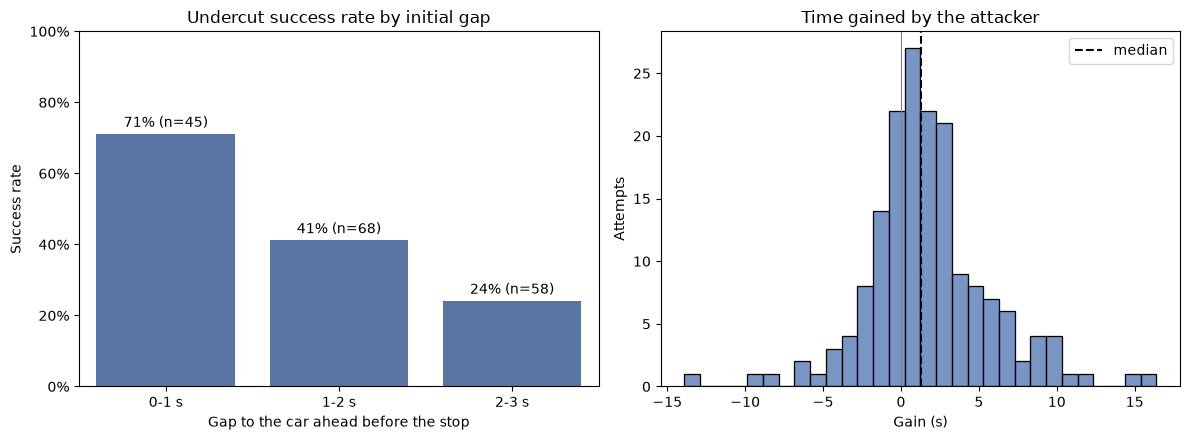

,attempts,success_rate,median_gain_s
gap_band,,,
0-1 s,45,0.71,2.58
1-2 s,68,0.41,0.64
2-3 s,58,0.24,0.86


In [7]:
attempts["gap_band"] = pd.cut(
    attempts["gap_before_s"], bins=[0, 1, 2, 3], labels=["0-1 s", "1-2 s", "2-3 s"]
)

by_gap = attempts.groupby("gap_band", observed=True).agg(
    attempts=("success", "size"),
    success_rate=("success", "mean"),
    median_gain_s=("gain_s", "median"),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(x=by_gap.index, y=by_gap["success_rate"], color="#4C72B0", ax=axes[0])
for i, (rate, n) in enumerate(zip(by_gap["success_rate"], by_gap["attempts"])):
    axes[0].text(i, rate + 0.02, f"{rate:.0%} (n={n})", ha="center")
axes[0].set_ylim(0, 1)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0].set_title("Undercut success rate by initial gap")
axes[0].set_xlabel("Gap to the car ahead before the stop")
axes[0].set_ylabel("Success rate")

sns.histplot(attempts["gain_s"], bins=30, color="#4C72B0", ax=axes[1])
axes[1].axvline(attempts["gain_s"].median(), color="black", linestyle="--", label="median")
axes[1].axvline(0, color="grey", linewidth=0.8)
axes[1].set_title("Time gained by the attacker")
axes[1].set_xlabel("Gain (s)")
axes[1].set_ylabel("Attempts")
axes[1].legend()

fig.tight_layout()
fig.savefig(IMAGES_DIR / "undercut_success_by_gap.png", dpi=150, bbox_inches="tight")
plt.show()

by_gap.round(2)

### Findings

- **171 undercut attempts** in 2023-2026 after excluding stops for rain, attempts disturbed by a neutralisation, abnormal stops (14) and on-track incidents (4).
- **The undercut works in 43% of attempts**, with a median gain of 1.26 s.
- **The initial gap decides**: 71% success within 1 s of the car ahead, 41% between 1 and 2 s, 24% between 2 and 3 s.
- **Close cars gain more** (median 2.6 s within 1 s, against 0.6-0.9 s further back). A likely explanation is dirty air: a car following closely loses grip in the wake of the car ahead, and pitting first also frees it from that.

**Limits.** Gaps are rebuilt from lap start times, precise to about 0.05 s. The 20 s threshold for incidents and the 5 s threshold for abnormal stops are judgement calls. Success is measured two laps after the defender's stop: a position gained can still be lost later.